# Phase 5 - Super-Clustering Contextual v4 (Transfer Learning)

Objetivo: mejorar generalizacion con transferencia multi-divisa.

Pipeline:
1. Construir secuencias de tokens desde `segment_cluster_assignments` de EURUSD y GBPUSD (phase4 v2).
2. Pretraining MLM contextual en `EURUSD + GBPUSD(train)`
3. Fine-tuning en GBPUSD (train/val) con early stopping.
4. Super-clustering sobre embeddings GBPUSD y evaluacion economica en test temporal.

In [1]:
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from scipy.stats import kruskal, f_oneway

pd.set_option('display.max_columns', 280)
pd.set_option('display.width', 320)


In [2]:
# =========================
# Config
# =========================
TARGET_SYMBOL = 'GBPUSD'
SOURCE_SYMBOLS = ['EURUSD']
ALL_SYMBOLS = SOURCE_SYMBOLS + [TARGET_SYMBOL]
SEQ_LEN = 32
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

# Model
D_MODEL = 96
N_HEAD = 4
N_LAYERS = 3
FF_DIM = 192
DROPOUT = 0.12
EMB_DIM = 64
DELTA_BINS = 24
SIGN_BINS = 3
MASK_PROB_PRE = 0.18
MASK_PROB_FT = 0.15
BATCH_SIZE = 64
EPOCHS_PRE = 24
EPOCHS_FT = 32
LR_PRE = 8e-4
LR_FT = 4e-4
WEIGHT_DECAY = 1e-4
PATIENCE_FT = 8
LABEL_SMOOTH = 0.02

# Clustering
K_CANDIDATES = list(range(4, 13))
KMEANS_SEEDS = [11, 42, 77]
N_INIT_KMEANS = 40
HORIZON_HOURS = 24
MIN_CLUSTER_N = 20

PHASE4_ROOT = Path('./phases/phase04_transfer_clustering')
PRICE_DIR = Path('./data/Dataset_H1_v1/parquet_h1')
PREV_SUMMARY_PATH = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_superclustering_summary.json')

OUT_DIR = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v4_transfer')
OUT_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_CSV = OUT_DIR / 'GBPUSD_transfer_train_history_v4.csv'
ENCODER_PT = OUT_DIR / 'GBPUSD_transfer_context_encoder_v4.pt'
WINDOWS_PQ = OUT_DIR / 'multi_fx_windows_len32.parquet'
MODEL_SELECTION_CSV = OUT_DIR / 'GBPUSD_superclustering_model_selection_v4.csv'
EMB_PQ = OUT_DIR / 'GBPUSD_context_window_embeddings_v4.parquet'
EMB_CSV = OUT_DIR / 'GBPUSD_context_window_embeddings_v4.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_regime_profile_v4.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_regime_transition_matrix_v4.csv'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_superclustering_summary_v4.json'

print('TARGET_SYMBOL =', TARGET_SYMBOL)
print('SOURCE_SYMBOLS =', SOURCE_SYMBOLS)
print('DEVICE =', DEVICE)
print('OUT_DIR =', OUT_DIR)


TARGET_SYMBOL = GBPUSD
SOURCE_SYMBOLS = ['EURUSD']
DEVICE = cuda
OUT_DIR = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v4_transfer


In [3]:
# =========================
# Helpers
# =========================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def pip_size(symbol: str) -> float:
    return 0.01 if str(symbol).upper().endswith('JPY') else 0.0001

def temporal_split(n: int, train_ratio: float, val_ratio: float):
    tr_end = int(n * train_ratio)
    va_end = int(n * (train_ratio + val_ratio))
    tr_end = max(1, min(tr_end, n - 2))
    va_end = max(tr_end + 1, min(va_end, n - 1))
    idx_train = np.arange(0, tr_end)
    idx_val = np.arange(tr_end, va_end)
    idx_test = np.arange(va_end, n)
    return idx_train, idx_val, idx_test

def zscore_col(x: pd.Series, eps: float = 1e-9):
    m = float(x.mean())
    s = float(x.std(ddof=0))
    if not np.isfinite(s) or s < eps:
        return pd.Series(np.zeros(len(x)), index=x.index, dtype=float)
    return (x - m) / (s + eps)

def load_assignments(symbol: str) -> pd.DataFrame:
    p = PHASE4_ROOT / f'output_transfer_{symbol}_full_v2' / f'{symbol}_segment_cluster_assignments.parquet'
    if not p.exists():
        raise FileNotFoundError(f'Missing assignments for {symbol}: {p}')
    d = pd.read_parquet(p).copy()
    d['start_ts'] = pd.to_datetime(d['start_ts'], errors='coerce')
    d['end_ts'] = pd.to_datetime(d['end_ts'], errors='coerce')
    d = d.sort_values(['start_ts', 'global_segment_id']).reset_index(drop=True)
    d['symbol'] = symbol
    return d

def build_stream(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy().sort_values(['start_ts', 'global_segment_id']).reset_index(drop=True)
    d['cluster_id'] = d['cluster_id'].astype(int)
    d['token'] = d['cluster_id'].map(lambda x: f'c{x:02d}')
    d['event_idx'] = np.arange(len(d), dtype=int)
    d['delta_prev_h'] = ((d['start_ts'] - d['start_ts'].shift(1)) / np.timedelta64(1, 'h')).fillna(0.0).astype(float)
    d['move_sign'] = np.sign(pd.to_numeric(d['move_pips'], errors='coerce').fillna(0.0)).astype(int)
    return d

def build_windows(stream_df: pd.DataFrame, seq_len: int = 32, stride: int = 1) -> pd.DataFrame:
    d = stream_df.sort_values('start_ts').reset_index(drop=True)
    rows = []
    if len(d) < seq_len:
        return pd.DataFrame(columns=['window_id','symbol','start_ts','end_ts','token_seq','delta_h_seq','move_sign_seq'])
    for i in range(0, len(d) - seq_len + 1, stride):
        w = d.iloc[i:i+seq_len]
        rows.append({
            'window_id': int(i),
            'symbol': str(w['symbol'].iloc[0]),
            'start_ts': pd.Timestamp(w['start_ts'].iloc[0]),
            'end_ts': pd.Timestamp(w['start_ts'].iloc[-1]),
            'token_seq': w['token'].astype(str).tolist(),
            'delta_h_seq': pd.to_numeric(w['delta_prev_h'], errors='coerce').fillna(0.0).astype(float).tolist(),
            'move_sign_seq': pd.to_numeric(w['move_sign'], errors='coerce').fillna(0).astype(int).tolist(),
        })
    return pd.DataFrame(rows)

def delta_to_bins(delta_arr: np.ndarray, delta_max: float, n_bins: int):
    x = np.asarray(delta_arr, dtype=float)
    x = np.clip(x, 0.0, max(1e-6, float(delta_max)))
    z = np.log1p(x) / np.log1p(max(1e-6, float(delta_max)))
    b = np.floor(z * (n_bins - 1 + 1e-12)).astype(int)
    return np.clip(b, 0, n_bins - 1)

def compute_forward_pips(df_price: pd.DataFrame, ts_vec: pd.Series, symbol: str, horizon_hours: int = 24):
    idx = df_price['timestamp'].to_numpy(dtype='datetime64[ns]')
    close = df_price['close'].to_numpy(dtype=float)
    ts = pd.to_datetime(ts_vec, errors='coerce').to_numpy(dtype='datetime64[ns]')
    pos = np.searchsorted(idx, ts, side='left')
    out = np.full(len(ts), np.nan, dtype=float)
    ps = pip_size(symbol)
    for i in range(len(ts)):
        p0 = pos[i]
        p1 = p0 + int(horizon_hours)
        if p0 < 0 or p1 >= len(idx):
            continue
        if idx[p0] != ts[i]:
            continue
        out[i] = (close[p1] - close[p0]) / ps
    return out

def make_masked_inputs(x: torch.Tensor, vocab_size: int, mask_id: int, mask_prob: float = 0.15):
    labels = x.clone()
    prob = torch.rand_like(x.float())
    masked = prob < mask_prob
    labels[~masked] = -100
    x_in = x.clone()
    if masked.any():
        r = torch.rand_like(x.float())
        mask_pos = masked & (r < 0.8)
        rand_pos = masked & (r >= 0.8) & (r < 0.9)
        x_in[mask_pos] = mask_id
        if rand_pos.any():
            rnd = torch.randint(low=0, high=vocab_size, size=(rand_pos.sum().item(),), device=x.device)
            x_in[rand_pos] = rnd
    return x_in, labels


In [4]:
# =========================
# Build multi-FX windows
# =========================
all_win = []
for sym in ALL_SYMBOLS:
    a = load_assignments(sym)
    s = build_stream(a)
    w = build_windows(s, seq_len=SEQ_LEN, stride=1)
    w['symbol'] = sym
    all_win.append(w)
    print(sym, 'segments=', len(s), 'windows=', len(w))

W_ALL = pd.concat(all_win, ignore_index=True)
W_ALL = W_ALL.sort_values(['symbol', 'start_ts', 'window_id']).reset_index(drop=True)

# target split (temporal by symbol target)
W_T = W_ALL[W_ALL['symbol'] == TARGET_SYMBOL].copy().sort_values('start_ts').reset_index(drop=True)
idx_tr_t, idx_va_t, idx_te_t = temporal_split(len(W_T), TRAIN_RATIO, VAL_RATIO)
spl_t = np.array(['train'] * len(W_T), dtype=object)
spl_t[idx_va_t] = 'val'
spl_t[idx_te_t] = 'test'
W_T['split'] = spl_t

# source uses all as pretrain_source
W_S = W_ALL[W_ALL['symbol'].isin(SOURCE_SYMBOLS)].copy().sort_values(['symbol', 'start_ts']).reset_index(drop=True)
W_S['split'] = 'pretrain_source'

W = pd.concat([W_S, W_T], ignore_index=True)
W = W.sort_values(['symbol', 'start_ts']).reset_index(drop=True)
W.to_parquet(WINDOWS_PQ, index=False)

print('total windows =', len(W))
print('target split counts:')
print(W_T['split'].value_counts().to_string())
display(W.head(3))


EURUSD segments= 1748 windows= 1717


GBPUSD segments= 1636 windows= 1605
total windows = 3322
target split counts:
split
train    1123
val       241
test      241


,window_id,symbol,start_ts,end_ts,token_seq,delta_h_seq,move_sign_seq,split
0,0,EURUSD,2000-05-31 04:00:00,2000-09-05 00:00:00,"[c07, c02, c01, c01, c06, c05, c01, c05, c01, ...","[0.0, 18.0, 22.0, 97.0, 50.0, 27.0, 90.0, 49.0...","[1, -1, 1, 1, -1, -1, 1, -1, 1, -1, -1, -1, 1,...",pretrain_source
1,1,EURUSD,2000-05-31 22:00:00,2000-09-06 05:00:00,"[c02, c01, c01, c06, c05, c01, c05, c01, c02, ...","[18.0, 22.0, 97.0, 50.0, 27.0, 90.0, 49.0, 21....","[-1, 1, 1, -1, -1, 1, -1, 1, -1, -1, -1, 1, -1...",pretrain_source
2,2,EURUSD,2000-06-01 20:00:00,2000-09-07 02:00:00,"[c01, c01, c06, c05, c01, c05, c01, c02, c05, ...","[22.0, 97.0, 50.0, 27.0, 90.0, 49.0, 21.0, 76....","[1, 1, -1, -1, 1, -1, 1, -1, -1, -1, 1, -1, -1...",pretrain_source


In [5]:
# =========================
# Encode arrays + split indices
# =========================
# global vocab from tokens in windows
tokens = sorted({str(t) for row in W['token_seq'] for t in row})
token_to_id = {t: i for i, t in enumerate(tokens)}
vocab_size = len(token_to_id)
mask_id = vocab_size
cls_id = vocab_size + 1

symbol_to_id = {s: i for i, s in enumerate(sorted(W['symbol'].unique().tolist()))}
num_symbols = len(symbol_to_id)

tok = np.vstack([np.array([token_to_id[str(t)] for t in row], dtype=np.int64) for row in W['token_seq']])
dlt = np.vstack([np.asarray(row, dtype=float) for row in W['delta_h_seq']])
sgn = np.vstack([np.asarray(row, dtype=int) for row in W['move_sign_seq']])
sgn = np.clip(sgn + 1, 0, 2).astype(np.int64)
sym = W['symbol'].map(symbol_to_id).to_numpy(dtype=np.int64)

# delta bins calibrated with target train only
target_mask = W['symbol'] == TARGET_SYMBOL
W_target_idx = np.where(target_mask.to_numpy())[0]
# positions in W for target splits
idx_target_train = W_target_idx[np.where(W.loc[target_mask, 'split'].to_numpy() == 'train')[0]]
idx_target_val = W_target_idx[np.where(W.loc[target_mask, 'split'].to_numpy() == 'val')[0]]
idx_target_test = W_target_idx[np.where(W.loc[target_mask, 'split'].to_numpy() == 'test')[0]]

delta_max = float(np.nanquantile(dlt[idx_target_train].reshape(-1), 0.99))
delta_max = max(1.0, delta_max)
dlt_bin = delta_to_bins(dlt, delta_max=delta_max, n_bins=DELTA_BINS).astype(np.int64)

# pretrain indices = source all + target train
idx_pretrain = np.where((W['split'] == 'pretrain_source') | ((W['symbol'] == TARGET_SYMBOL) & (W['split'] == 'train')))[0]

print('vocab_size =', vocab_size, '| num_symbols =', num_symbols)
print('idx_pretrain =', len(idx_pretrain))
print('idx_target_train/val/test =', len(idx_target_train), len(idx_target_val), len(idx_target_test))


vocab_size = 10 | num_symbols = 2
idx_pretrain = 2840
idx_target_train/val/test = 1123 241 241


In [6]:
# =========================
# Dataset + model
# =========================
class SeqDataset(Dataset):
    def __init__(self, tok_arr, dlt_arr, sgn_arr, sym_arr, indices):
        idx = np.asarray(indices, dtype=int)
        self.tok = torch.from_numpy(tok_arr[idx]).long()
        self.dlt = torch.from_numpy(dlt_arr[idx]).long()
        self.sgn = torch.from_numpy(sgn_arr[idx]).long()
        self.sym = torch.from_numpy(sym_arr[idx]).long()

    def __len__(self):
        return len(self.tok)

    def __getitem__(self, i):
        return self.tok[i], self.dlt[i], self.sgn[i], self.sym[i]


class ContextTransformerTL(nn.Module):
    def __init__(self, vocab_size, mask_id, cls_id, seq_len, d_model, n_head, n_layers, ff_dim, dropout, delta_bins, sign_bins, emb_dim, num_symbols):
        super().__init__()
        self.vocab_size = int(vocab_size)
        self.mask_id = int(mask_id)
        self.cls_id = int(cls_id)

        self.token_emb = nn.Embedding(vocab_size + 2, d_model)
        self.delta_emb = nn.Embedding(delta_bins, d_model)
        self.sign_emb = nn.Embedding(sign_bins, d_model)
        self.sym_emb = nn.Embedding(num_symbols, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, seq_len + 1, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.to_emb = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, emb_dim),
        )
        self.mlm_head = nn.Linear(d_model, vocab_size)

    def forward(self, tok_ids, dlt_ids, sgn_ids, sym_ids):
        B = tok_ids.shape[0]
        cls_tok = torch.full((B, 1), self.cls_id, device=tok_ids.device, dtype=torch.long)
        cls_dlt = torch.zeros((B, 1), device=dlt_ids.device, dtype=torch.long)
        cls_sgn = torch.ones((B, 1), device=sgn_ids.device, dtype=torch.long)

        t = torch.cat([cls_tok, tok_ids], dim=1)
        d = torch.cat([cls_dlt, dlt_ids], dim=1)
        s = torch.cat([cls_sgn, sgn_ids], dim=1)

        sym_vec = self.sym_emb(sym_ids).unsqueeze(1)
        h = self.token_emb(t) + self.delta_emb(d) + self.sign_emb(s) + sym_vec
        h = h + self.pos_emb[:, :h.shape[1], :]
        h = self.encoder(h)

        cls_h = h[:, 0, :]
        z = self.to_emb(cls_h)
        logits = self.mlm_head(h[:, 1:, :])
        return logits, z

    def encode(self, tok_ids, dlt_ids, sgn_ids, sym_ids):
        _, z = self.forward(tok_ids, dlt_ids, sgn_ids, sym_ids)
        return z


In [7]:
# =========================
# Pretraining + Fine-tuning
# =========================
pin = DEVICE == 'cuda'
pre_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, sym, idx_pretrain), batch_size=BATCH_SIZE, shuffle=True, pin_memory=pin)
ft_train_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, sym, idx_target_train), batch_size=BATCH_SIZE, shuffle=True, pin_memory=pin)
ft_val_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, sym, idx_target_val), batch_size=BATCH_SIZE, shuffle=False, pin_memory=pin)

model = ContextTransformerTL(
    vocab_size=vocab_size,
    mask_id=mask_id,
    cls_id=cls_id,
    seq_len=SEQ_LEN,
    d_model=D_MODEL,
    n_head=N_HEAD,
    n_layers=N_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
    delta_bins=DELTA_BINS,
    sign_bins=SIGN_BINS,
    emb_dim=EMB_DIM,
    num_symbols=num_symbols,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(ignore_index=-100, label_smoothing=LABEL_SMOOTH)

history = []

# ---- Stage A: Pretraining ----
opt_pre = torch.optim.AdamW(model.parameters(), lr=LR_PRE, weight_decay=WEIGHT_DECAY)
sch_pre = torch.optim.lr_scheduler.CosineAnnealingLR(opt_pre, T_max=EPOCHS_PRE, eta_min=LR_PRE * 0.1)

for ep in range(1, EPOCHS_PRE + 1):
    model.train()
    losses = []
    for xb_tok, xb_dlt, xb_sgn, xb_sym in pre_loader:
        xb_tok = xb_tok.to(DEVICE, non_blocking=True)
        xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
        xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)
        xb_sym = xb_sym.to(DEVICE, non_blocking=True)

        x_in, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB_PRE)

        opt_pre.zero_grad(set_to_none=True)
        logits, _ = model(x_in, xb_dlt, xb_sgn, xb_sym)
        loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt_pre.step()
        losses.append(float(loss.detach().cpu().item()))

    sch_pre.step()
    tr = float(np.mean(losses)) if losses else np.nan
    history.append({'stage': 'pretrain', 'epoch': ep, 'train_loss': tr, 'val_loss': np.nan, 'lr': opt_pre.param_groups[0]['lr']})
    if ep == 1 or ep % 4 == 0 or ep == EPOCHS_PRE:
        print(f'[pre] ep={ep:03d} train={tr:.6f} lr={opt_pre.param_groups[0]["lr"]:.6g}')

# ---- Stage B: Fine-tuning on target ----
opt_ft = torch.optim.AdamW(model.parameters(), lr=LR_FT, weight_decay=WEIGHT_DECAY)
sch_ft = torch.optim.lr_scheduler.CosineAnnealingLR(opt_ft, T_max=EPOCHS_FT, eta_min=LR_FT * 0.1)

best_val = float('inf')
best_state = None
bad = 0

for ep in range(1, EPOCHS_FT + 1):
    model.train()
    tr_losses = []
    for xb_tok, xb_dlt, xb_sgn, xb_sym in ft_train_loader:
        xb_tok = xb_tok.to(DEVICE, non_blocking=True)
        xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
        xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)
        xb_sym = xb_sym.to(DEVICE, non_blocking=True)

        x_in, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB_FT)

        opt_ft.zero_grad(set_to_none=True)
        logits, _ = model(x_in, xb_dlt, xb_sgn, xb_sym)
        loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt_ft.step()
        tr_losses.append(float(loss.detach().cpu().item()))

    sch_ft.step()
    tr = float(np.mean(tr_losses)) if tr_losses else np.nan

    model.eval()
    va_losses = []
    with torch.no_grad():
        for xb_tok, xb_dlt, xb_sgn, xb_sym in ft_val_loader:
            xb_tok = xb_tok.to(DEVICE, non_blocking=True)
            xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
            xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)
            xb_sym = xb_sym.to(DEVICE, non_blocking=True)
            x_in, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB_FT)
            logits, _ = model(x_in, xb_dlt, xb_sgn, xb_sym)
            loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
            va_losses.append(float(loss.detach().cpu().item()))

    va = float(np.mean(va_losses)) if va_losses else np.nan

    if np.isfinite(va) and va < best_val - 1e-6:
        best_val = va
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        bad = 0
    else:
        bad += 1

    history.append({'stage': 'finetune', 'epoch': ep, 'train_loss': tr, 'val_loss': va, 'lr': opt_ft.param_groups[0]['lr']})

    if ep == 1 or ep % 3 == 0 or ep == EPOCHS_FT:
        print(f'[ft ] ep={ep:03d} train={tr:.6f} val={va:.6f} lr={opt_ft.param_groups[0]["lr"]:.6g}')

    if bad >= PATIENCE_FT and ep >= 10:
        print(f'Early stopping FT at ep={ep}')
        break

if best_state is not None:
    model.load_state_dict(best_state)

torch.save({'state_dict': model.state_dict(), 'config': {
    'seq_len': SEQ_LEN, 'd_model': D_MODEL, 'n_head': N_HEAD, 'n_layers': N_LAYERS,
    'ff_dim': FF_DIM, 'dropout': DROPOUT, 'emb_dim': EMB_DIM, 'delta_bins': DELTA_BINS,
    'sign_bins': SIGN_BINS, 'vocab_size': vocab_size, 'mask_id': mask_id, 'cls_id': cls_id,
    'num_symbols': num_symbols, 'delta_max': delta_max,
}}, ENCODER_PT)

HIST = pd.DataFrame(history)
HIST.to_csv(HISTORY_CSV, index=False)
print('best_val_ft =', best_val)
print('saved encoder =', ENCODER_PT)
print('saved history =', HISTORY_CSV)


[pre] ep=001 train=1.623212 lr=0.00079692


[pre] ep=004 train=1.388748 lr=0.000751769


[pre] ep=008 train=1.313753 lr=0.00062


[pre] ep=012 train=1.239483 lr=0.00044


[pre] ep=016 train=1.153090 lr=0.00026


...

[pre] ep=024 train=1.079366 lr=8e-05
[ft ] ep=001 train=1.073233 val=1.792261 lr=0.000399133


[ft ] ep=003 train=1.051832 val=1.768980 lr=0.000392249


[ft ] ep=006 train=0.992666 val=1.840183 lr=0.000369665


[ft ] ep=009 train=0.982368 val=1.952662 lr=0.000334191


Early stopping FT at ep=11
best_val_ft = 1.7689796686172485
saved encoder = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v4_transfer/GBPUSD_transfer_context_encoder_v4.pt
saved history = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v4_transfer/GBPUSD_transfer_train_history_v4.csv


In [8]:
# =========================
# Encode target windows only
# =========================
model.eval()

# indices in W that belong to target symbol
idx_target_all = np.where(W['symbol'].to_numpy() == TARGET_SYMBOL)[0]

def encode_indices(indices, bs=256):
    out = []
    with torch.no_grad():
        for i in range(0, len(indices), bs):
            idx = indices[i:i+bs]
            xb_tok = torch.from_numpy(tok[idx]).long().to(DEVICE)
            xb_dlt = torch.from_numpy(dlt_bin[idx]).long().to(DEVICE)
            xb_sgn = torch.from_numpy(sgn[idx]).long().to(DEVICE)
            xb_sym = torch.from_numpy(sym[idx]).long().to(DEVICE)
            z = model.encode(xb_tok, xb_dlt, xb_sgn, xb_sym)
            out.append(z.detach().cpu().numpy())
    return np.vstack(out).astype(np.float32)

Z_t = encode_indices(idx_target_all)
W_T2 = W.iloc[idx_target_all].copy().reset_index(drop=True)

# map split-local target indices
idx_tr = np.where(W_T2['split'].to_numpy() == 'train')[0]
idx_va = np.where(W_T2['split'].to_numpy() == 'val')[0]
idx_te = np.where(W_T2['split'].to_numpy() == 'test')[0]

print('target windows =', len(W_T2), '| Z_t shape =', Z_t.shape)
print('split counts: train/val/test =', len(idx_tr), len(idx_va), len(idx_te))


target windows = 1605 | Z_t shape = (1605, 64)
split counts: train/val/test = 1123 241 241


In [9]:
# =========================
# Robust K selection (val geometry + val economics)
# =========================
sc = StandardScaler()
Ztr = sc.fit_transform(Z_t[idx_tr])
Zva = sc.transform(Z_t[idx_va])

PX = pd.read_parquet(PRICE_DIR / f'{TARGET_SYMBOL}.parquet', columns=['timestamp','close']).copy()
PX['timestamp'] = pd.to_datetime(PX['timestamp'], errors='coerce')
PX['close'] = pd.to_numeric(PX['close'], errors='coerce')
PX = PX.dropna().sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)
ret_val = compute_forward_pips(PX, W_T2.iloc[idx_va]['end_ts'], symbol=TARGET_SYMBOL, horizon_hours=HORIZON_HOURS)

rows = []
for k in K_CANDIDATES:
    seed_labels = {}
    sils, chs, dbs = [], [], []

    for sd in KMEANS_SEEDS:
        km = KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=sd)
        km.fit(Ztr)
        lv = km.predict(Zva)
        seed_labels[sd] = lv
        if len(np.unique(lv)) >= 2 and len(lv) > k:
            sils.append(float(silhouette_score(Zva, lv)))
            chs.append(float(calinski_harabasz_score(Zva, lv)))
            dbs.append(float(davies_bouldin_score(Zva, lv)))

    aris = []
    seeds = list(seed_labels.keys())
    for i in range(len(seeds)):
        for j in range(i+1, len(seeds)):
            aris.append(float(adjusted_rand_score(seed_labels[seeds[i]], seed_labels[seeds[j]])))

    lv = seed_labels[42]
    ok = np.isfinite(ret_val)
    groups = []
    for cid in np.unique(lv[ok]):
        x = ret_val[ok][lv[ok] == cid]
        if len(x) >= MIN_CLUSTER_N:
            groups.append(x)

    val_kw = np.nan
    val_eta2 = np.nan
    if len(groups) >= 2:
        val_kw = float(kruskal(*groups).pvalue)
        all_vals = np.concatenate(groups)
        gm = np.mean(all_vals)
        ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
        sst = np.sum((all_vals - gm) ** 2)
        val_eta2 = float(ssb / sst) if sst > 0 else np.nan

    rows.append({
        'k': int(k),
        'sil_val_mean': float(np.mean(sils)) if len(sils) else np.nan,
        'ch_val_mean': float(np.mean(chs)) if len(chs) else np.nan,
        'db_val_mean': float(np.mean(dbs)) if len(dbs) else np.nan,
        'stability_ari_mean': float(np.mean(aris)) if len(aris) else np.nan,
        'val_kw_p': val_kw,
        'val_eta2': val_eta2,
    })

SEL = pd.DataFrame(rows)
SEL['z_sil'] = zscore_col(SEL['sil_val_mean'])
SEL['z_ch'] = zscore_col(SEL['ch_val_mean'])
SEL['z_db'] = zscore_col(SEL['db_val_mean'])
SEL['z_ari'] = zscore_col(SEL['stability_ari_mean'])
SEL['z_val_eta2'] = zscore_col(SEL['val_eta2'].fillna(0.0))
SEL['robust_score'] = SEL['z_sil'] + 0.8 * SEL['z_ch'] - 0.8 * SEL['z_db'] + 0.6 * SEL['z_ari'] + 0.9 * SEL['z_val_eta2']
SEL = SEL.sort_values('robust_score', ascending=False, na_position='last').reset_index(drop=True)
SEL.to_csv(MODEL_SELECTION_CSV, index=False)
BEST_K = int(SEL.iloc[0]['k'])

print('BEST_K =', BEST_K)
display(SEL)


BEST_K = 4


,k,sil_val_mean,ch_val_mean,db_val_mean,stability_ari_mean,val_kw_p,val_eta2,z_sil,z_ch,z_db,z_ari,z_val_eta2,robust_score
0,4,0.105131,37.639152,1.674261,1.000000,0.115603,0.022665,-0.076520,0.855936,-0.259410,1.287171,1.125667,2.601160
1,12,0.134798,34.034270,1.456253,0.774595,0.514547,0.018414,1.673455,-0.366517,-1.201330,-0.597735,0.327773,2.277659
2,6,0.124627,39.313948,1.977235,0.969361,0.411145,0.015577,1.073486,1.423877,1.049617,1.030963,-0.204708,1.807235
3,5,0.110927,39.906481,2.139568,0.985278,0.185790,0.021654,0.265384,1.624811,1.750992,1.164060,0.935774,1.705072
4,9,0.094627,33.048053,1.555459,0.805892,0.319740,0.018180,-0.696171,-0.700953,-0.772703,-0.336020,0.283882,-0.584889
5,8,0.116534,34.359303,1.638598,0.835032,0.816763,0.008253,0.596115,-0.256295,-0.413493,-0.092344,-1.579252,-0.754860
6,10,0.088970,33.874490,1.658404,0.782676,0.485320,0.020453,-1.029853,-0.420700,-0.327921,-0.530154,0.710403,-0.782806
7,11,0.076738,30.613834,1.499289,0.602376,0.534640,0.018181,-1.751376,-1.526422,-1.015393,-2.037879,0.284043,-3.127288
8,7,0.105504,33.246264,2.009643,0.859460,0.837976,0.006632,-0.054521,-0.633738,1.189639,0.111938,-1.883582,-3.141284


In [10]:
# =========================
# Final clustering + profiling on target
# =========================
idx_trainval = np.concatenate([idx_tr, idx_va])
Z_trainval = sc.fit_transform(Z_t[idx_trainval])
Z_all = sc.transform(Z_t)

KM = KMeans(n_clusters=BEST_K, n_init=N_INIT_KMEANS, random_state=SEED)
KM.fit(Z_trainval)
reg = KM.predict(Z_all)
dist = KM.transform(Z_all).min(axis=1)

OUT = W_T2[['window_id','symbol','start_ts','end_ts','split']].copy()
OUT['regime_id'] = reg.astype(int)
OUT['regime_dist'] = dist.astype(float)
OUT['regime_token'] = OUT['regime_id'].map(lambda x: f'r{x:02d}')

for j in range(Z_t.shape[1]):
    OUT[f'ctx_emb_{j:03d}'] = Z_t[:, j]

OUT['ret_fwd_24h_pips'] = compute_forward_pips(PX, OUT['end_ts'], symbol=TARGET_SYMBOL, horizon_hours=HORIZON_HOURS)

test_df = OUT[OUT['split'] == 'test'].copy()
prof = (test_df.groupby('regime_id')['ret_fwd_24h_pips']
        .agg(n='count', mean_ret='mean', median_ret='median', std_ret='std')
        .reset_index())
prof['t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
prof = prof.sort_values('n', ascending=False).reset_index(drop=True)

groups = []
for rid, g in test_df.groupby('regime_id'):
    x = g['ret_fwd_24h_pips'].dropna().to_numpy()
    if len(x) >= MIN_CLUSTER_N:
        groups.append(x)

kw_p = np.nan
anova_p = np.nan
eta2 = np.nan
if len(groups) >= 2:
    kw_p = float(kruskal(*groups).pvalue)
    anova_p = float(f_oneway(*groups).pvalue)
    all_vals = np.concatenate(groups)
    gm = np.mean(all_vals)
    ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
    sst = np.sum((all_vals - gm) ** 2)
    eta2 = float(ssb / sst) if sst > 0 else np.nan

tr = pd.crosstab(OUT['regime_token'], OUT['regime_token'].shift(-1)).fillna(0)
tr_prob = tr.div(tr.sum(axis=1), axis=0).fillna(0.0)

OUT.to_parquet(EMB_PQ, index=False)
OUT.to_csv(EMB_CSV, index=False)
prof.to_csv(PROFILE_CSV, index=False)
tr_prob.to_csv(TRANS_CSV)

summary = {
    'symbol': TARGET_SYMBOL,
    'model_tag': 'v4_transfer',
    'source_symbols': SOURCE_SYMBOLS,
    'n_windows_target': int(len(W_T2)),
    'split_counts': {k: int(v) for k, v in OUT['split'].value_counts().to_dict().items()},
    'best_k': int(BEST_K),
    'kw_pvalue_test': None if not np.isfinite(kw_p) else float(kw_p),
    'anova_pvalue_test': None if not np.isfinite(anova_p) else float(anova_p),
    'eta2_test': None if not np.isfinite(eta2) else float(eta2),
    'best_k_robust_score': float(SEL.iloc[0]['robust_score']),
    'best_k_val_eta2': None if not np.isfinite(SEL.iloc[0]['val_eta2']) else float(SEL.iloc[0]['val_eta2']),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved embeddings =', EMB_PQ)
print('saved profile =', PROFILE_CSV)
print('saved transitions =', TRANS_CSV)
print('BEST_K =', BEST_K, '| kw_p =', kw_p, '| eta2 =', eta2)
display(prof)


saved embeddings = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v4_transfer/GBPUSD_context_window_embeddings_v4.parquet
saved profile = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v4_transfer/GBPUSD_context_regime_profile_v4.csv
saved transitions = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v4_transfer/GBPUSD_context_regime_transition_matrix_v4.csv
BEST_K = 4 | kw_p = 0.15639297404661304 | eta2 = 0.02285252199305804


,regime_id,n,mean_ret,median_ret,std_ret,t_like
0,0,113,-2.505347,-6.099939,101.852621,-0.024598
1,3,68,-28.863181,-11.749864,131.764589,-0.219051
2,1,51,20.892153,10.699034,128.261470,0.162887
3,2,9,-42.700105,-21.899939,98.265439,-0.434538


In [11]:
# =========================
# Compare vs previous v2
# =========================
if PREV_SUMMARY_PATH.exists():
    prev = json.loads(PREV_SUMMARY_PATH.read_text())
    curr = json.loads(SUMMARY_JSON.read_text())
    CMP = pd.DataFrame([
        {'metric': 'best_k', 'v2': prev.get('best_k'), 'v4_transfer': curr.get('best_k')},
        {'metric': 'kw_pvalue_test', 'v2': prev.get('kw_pvalue_test'), 'v4_transfer': curr.get('kw_pvalue_test')},
        {'metric': 'anova_pvalue_test', 'v2': prev.get('anova_pvalue_test'), 'v4_transfer': curr.get('anova_pvalue_test')},
        {'metric': 'eta2_test', 'v2': prev.get('eta2_test'), 'v4_transfer': curr.get('eta2_test')},
    ])
    display(CMP)
else:
    print('No previous summary found at:', PREV_SUMMARY_PATH)


,metric,v2,v4_transfer
0,best_k,6.000000,4.000000
1,kw_pvalue_test,0.004396,0.156393
2,anova_pvalue_test,0.004857,0.070865
3,eta2_test,0.063914,0.022853


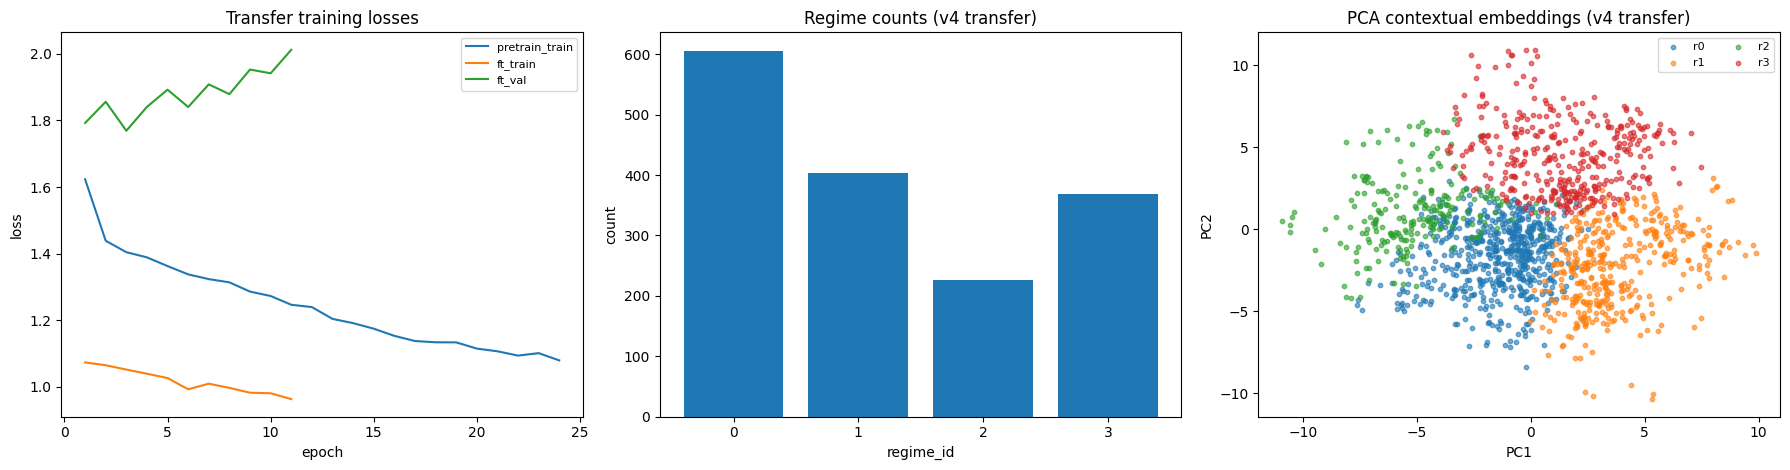

In [12]:
# =========================
# Diagnostics
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

h_pre = HIST[HIST['stage'] == 'pretrain']
h_ft = HIST[HIST['stage'] == 'finetune']
axes[0].plot(h_pre['epoch'], h_pre['train_loss'], label='pretrain_train')
axes[0].plot(h_ft['epoch'], h_ft['train_loss'], label='ft_train')
axes[0].plot(h_ft['epoch'], h_ft['val_loss'], label='ft_val')
axes[0].set_title('Transfer training losses')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend(fontsize=8)

cnt = OUT['regime_id'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('Regime counts (v4 transfer)')
axes[1].set_xlabel('regime_id')
axes[1].set_ylabel('count')

pca = PCA(n_components=2, random_state=SEED)
xy = pca.fit_transform(Z_all)
for rid in sorted(np.unique(OUT['regime_id'])):
    m = OUT['regime_id'].to_numpy() == rid
    axes[2].scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.6, label=f'r{rid}')
axes[2].set_title('PCA contextual embeddings (v4 transfer)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


## Salidas v4 transfer

- `GBPUSD_transfer_context_encoder_v4.pt`
- `GBPUSD_transfer_train_history_v4.csv`
- `multi_fx_windows_len32.parquet`
- `GBPUSD_superclustering_model_selection_v4.csv`
- `GBPUSD_context_window_embeddings_v4.parquet`
- `GBPUSD_context_regime_profile_v4.csv`
- `GBPUSD_context_regime_transition_matrix_v4.csv`
- `GBPUSD_superclustering_summary_v4.json`